# Task 2 (Beginner Version): SQL & Data Extraction from Basics
**ApexPlanet Software Pvt. Ltd. | Data Analytics Internship**
**Dataset:** IBM Telco Customer Churn (cleaned in Task 1)

**How to use this notebook:** run the cells **from top to bottom, one by one** (Shift+Enter). Every cell is self-contained here: no other files needed except your cleaned CSV.

**What you will learn:** SQL basics -> filtering -> grouping -> JOINs -> subqueries/CTEs -> window functions -> business queries -> views/indexes -> Python + SQL (parameterized queries).

> Telco has no order dates, so "monthly" means **tenure month** (months since the customer joined).

## Step 1: Import the tools
`sqlite3` is built into Python (a small database in one file). `pandas` turns query results into tables.

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Libraries ready. SQLite version:", sqlite3.sqlite_version)

Libraries ready. SQLite version: 3.50.4


## Step 2: Find your cleaned CSV from Task 1
If the cell cannot find it, paste the full path between the quotes in `MANUAL_PATH` and run it again.

In [2]:
MANUAL_PATH = ""     # example: r"C:\Users\YourName\Documents\apexplanet-data-analytics\data\processed\telco_churn_cleaned.csv"

if MANUAL_PATH:
    CSV_PATH = Path(MANUAL_PATH)
else:
    found = []
    for root in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        found = list(root.rglob("telco_churn_cleaned.csv"))
        if found:
            break
    if not found:
        raise FileNotFoundError("telco_churn_cleaned.csv not found. Put it in data/processed/ or set MANUAL_PATH above.")
    CSV_PATH = found[0]

DB_PATH = CSV_PATH.parent.parent / "telco.db" if CSV_PATH.parent.name == "processed" else CSV_PATH.parent / "telco.db"
FIG_DIR = DB_PATH.parent / "figures_task2"
FIG_DIR.mkdir(exist_ok=True)
print("CSV found :", CSV_PATH)
print("Database  :", DB_PATH)

CSV found : c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\data\processed\telco_churn_cleaned.csv
Database  : c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\data\telco.db


## Step 3: Connect Python to the database
A *connection* is the link between Python and the database file. If the file does not exist, SQLite creates it.

In [3]:
conn = sqlite3.connect(DB_PATH)
print("Connected to:", DB_PATH.name)

Connected to: telco.db


## Step 4: Two helper functions (you will use them all notebook)
- `q(sql)` runs a **SELECT** and shows the result as a table.
- `run(sql)` runs commands that change the database (CREATE, DROP, INSERT...).

In [4]:
def q(sql, params=None):
    """Run a SELECT query and show the result as a pandas table."""
    df = pd.read_sql_query(sql, conn, params=params)
    display(df)
    return df

def run(sql):
    """Run one or many SQL commands that change the database."""
    conn.executescript(sql)
    conn.commit()

print("Helpers ready: q() and run()")

Helpers ready: q() and run()


## Step 5: Load the cleaned CSV into a database table
`df.to_sql` copies the DataFrame into a table called `telco_clean`.

In [5]:
df = pd.read_csv(CSV_PATH)
df.to_sql("telco_clean", conn, if_exists="replace", index=False)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns into table 'telco_clean'")
df.columns.tolist()

Loaded 7,043 rows and 22 columns into table 'telco_clean'


['customer_id',
 'gender',
 'senior_citizen',
 'partner',
 'dependents',
 'tenure',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method',
 'monthly_charges',
 'total_charges',
 'churn',
 'churn_flag']

# PART A: SQL Basics

### A1. SELECT * ... LIMIT
`SELECT *` means *all columns*. `LIMIT 5` keeps only 5 rows so the output stays small.

In [6]:
q("""
SELECT *
FROM telco_clean
LIMIT 5
""")

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,churn_flag
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,churn_flag
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


### A2. Choose specific columns
List only the columns you need, separated by commas.

In [7]:
q("""
SELECT customer_id, contract, tenure, monthly_charges
FROM telco_clean
LIMIT 10
""")

,customer_id,contract,tenure,monthly_charges
0,7590-VHVEG,Month-to-month,1,29.85
1,5575-GNVDE,One year,34,56.95
2,3668-QPYBK,Month-to-month,2,53.85
3,7795-CFOCW,One year,45,42.30
4,9237-HQITU,Month-to-month,2,70.70
5,9305-CDSKC,Month-to-month,8,99.65
6,1452-KIOVK,Month-to-month,22,89.10
7,6713-OKOMC,Month-to-month,10,29.75
8,7892-POOKP,Month-to-month,28,104.80
9,6388-TABGU,One year,62,56.15


,customer_id,contract,tenure,monthly_charges
0,7590-VHVEG,Month-to-month,1,29.85
1,5575-GNVDE,One year,34,56.95
2,3668-QPYBK,Month-to-month,2,53.85
3,7795-CFOCW,One year,45,42.30
4,9237-HQITU,Month-to-month,2,70.70
5,9305-CDSKC,Month-to-month,8,99.65
6,1452-KIOVK,Month-to-month,22,89.10
7,6713-OKOMC,Month-to-month,10,29.75
8,7892-POOKP,Month-to-month,28,104.80
9,6388-TABGU,One year,62,56.15


### A3. COUNT: how many rows?
`COUNT(*)` counts rows. `AS` gives the result column a friendly name.

In [8]:
q("""
SELECT COUNT(*) AS total_customers
FROM telco_clean
""")

,total_customers
0,7043


,total_customers
0,7043


### A4. WHERE: filter rows
`WHERE` keeps only rows that match. Combine conditions with `AND` / `OR`.

In [9]:
q("""
SELECT customer_id, contract, tenure, monthly_charges
FROM telco_clean
WHERE churn = 'Yes'
  AND contract = 'Month-to-month'
LIMIT 10
""")

,customer_id,contract,tenure,monthly_charges
0,3668-QPYBK,Month-to-month,2,53.85
1,9237-HQITU,Month-to-month,2,70.70
2,9305-CDSKC,Month-to-month,8,99.65
3,7892-POOKP,Month-to-month,28,104.80
4,0280-XJGEX,Month-to-month,49,103.70
5,4190-MFLUW,Month-to-month,10,55.20
6,8779-QRDMV,Month-to-month,1,39.65
7,1066-JKSGK,Month-to-month,1,20.15
8,6467-CHFZW,Month-to-month,47,99.35
9,8665-UTDHZ,Month-to-month,1,30.20


,customer_id,contract,tenure,monthly_charges
0,3668-QPYBK,Month-to-month,2,53.85
1,9237-HQITU,Month-to-month,2,70.70
2,9305-CDSKC,Month-to-month,8,99.65
3,7892-POOKP,Month-to-month,28,104.80
4,0280-XJGEX,Month-to-month,49,103.70
5,4190-MFLUW,Month-to-month,10,55.20
6,8779-QRDMV,Month-to-month,1,39.65
7,1066-JKSGK,Month-to-month,1,20.15
8,6467-CHFZW,Month-to-month,47,99.35
9,8665-UTDHZ,Month-to-month,1,30.20


### A5. More filters: BETWEEN, IN, LIKE
`BETWEEN` = range, `IN` = one of a list, `LIKE '%word%'` = text contains word.

In [10]:
q("""
SELECT customer_id, tenure, internet_service, payment_method
FROM telco_clean
WHERE tenure BETWEEN 1 AND 6
  AND internet_service IN ('DSL', 'Fiber optic')
  AND payment_method LIKE '%automatic%'
LIMIT 10
""")

,customer_id,tenure,internet_service,payment_method
0,4929-XIHVW,2,Fiber optic,Credit card (automatic)
1,3413-BMNZE,1,DSL,Bank transfer (automatic)
2,5630-AHZIL,3,DSL,Bank transfer (automatic)
3,3376-BMGFE,4,Fiber optic,Bank transfer (automatic)
4,6317-YPKDH,1,DSL,Bank transfer (automatic)
5,7841-TZDMQ,2,DSL,Credit card (automatic)
6,4959-JOSRX,2,DSL,Credit card (automatic)
7,6366-ZGQGL,1,DSL,Bank transfer (automatic)
8,4130-MZLCC,5,DSL,Bank transfer (automatic)
9,0219-YTZUE,4,Fiber optic,Bank transfer (automatic)


,customer_id,tenure,internet_service,payment_method
0,4929-XIHVW,2,Fiber optic,Credit card (automatic)
1,3413-BMNZE,1,DSL,Bank transfer (automatic)
2,5630-AHZIL,3,DSL,Bank transfer (automatic)
3,3376-BMGFE,4,Fiber optic,Bank transfer (automatic)
4,6317-YPKDH,1,DSL,Bank transfer (automatic)
5,7841-TZDMQ,2,DSL,Credit card (automatic)
6,4959-JOSRX,2,DSL,Credit card (automatic)
7,6366-ZGQGL,1,DSL,Bank transfer (automatic)
8,4130-MZLCC,5,DSL,Bank transfer (automatic)
9,0219-YTZUE,4,Fiber optic,Bank transfer (automatic)


### A6. ORDER BY + LIMIT: top 10
`ORDER BY ... DESC` sorts from highest to lowest.

In [11]:
q("""
SELECT customer_id, contract, monthly_charges, churn
FROM telco_clean
ORDER BY monthly_charges DESC
LIMIT 10
""")

,customer_id,contract,monthly_charges,churn
0,7569-NMZYQ,Two year,118.75,No
1,8984-HPEMB,Two year,118.65,No
2,5989-AXPUC,Two year,118.60,No
3,5734-EJKXG,One year,118.60,No
4,8199-ZLLSA,One year,118.35,Yes
5,9924-JPRMC,Two year,118.20,No
6,2889-FPWRM,One year,117.80,Yes
7,3810-DVDQQ,Two year,117.60,No
8,9739-JLPQJ,Two year,117.50,No
9,2302-ANTDP,Month-to-month,117.45,Yes


,customer_id,contract,monthly_charges,churn
0,7569-NMZYQ,Two year,118.75,No
1,8984-HPEMB,Two year,118.65,No
2,5989-AXPUC,Two year,118.60,No
3,5734-EJKXG,One year,118.60,No
4,8199-ZLLSA,One year,118.35,Yes
5,9924-JPRMC,Two year,118.20,No
6,2889-FPWRM,One year,117.80,Yes
7,3810-DVDQQ,Two year,117.60,No
8,9739-JLPQJ,Two year,117.50,No
9,2302-ANTDP,Month-to-month,117.45,Yes


### A7. DISTINCT: unique values
Shows each value only once.

In [12]:
q("""
SELECT DISTINCT contract
FROM telco_clean
""")

,contract
0,Month-to-month
1,One year
2,Two year


,contract
0,Month-to-month
1,One year
2,Two year


### A8. Aggregate functions
COUNT, SUM, AVG, MIN, MAX summarise many rows into one.

In [13]:
q("""
SELECT COUNT(*)                       AS customers,
       ROUND(SUM(monthly_charges), 2) AS total_monthly_revenue,
       ROUND(AVG(monthly_charges), 2) AS avg_bill,
       MIN(monthly_charges)           AS cheapest,
       MAX(monthly_charges)           AS most_expensive
FROM telco_clean
""")

,customers,total_monthly_revenue,avg_bill,cheapest,most_expensive
0,7043,456116.6,64.76,18.25,118.75


,customers,total_monthly_revenue,avg_bill,cheapest,most_expensive
0,7043,456116.6,64.76,18.25,118.75


### A9. GROUP BY: one summary per group
Churn rate = average of `churn_flag` (1 = churned) x 100.

In [14]:
q("""
SELECT contract,
       COUNT(*)                          AS customers,
       SUM(churn_flag)                   AS churned,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM telco_clean
GROUP BY contract
ORDER BY churn_rate_pct DESC
""")

,contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


,contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


### A10. GROUP BY two columns
Groups by every combination of contract and internet service.

In [15]:
q("""
SELECT contract, internet_service,
       COUNT(*)                          AS customers,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM telco_clean
GROUP BY contract, internet_service
ORDER BY churn_rate_pct DESC
""")

,contract,internet_service,customers,churn_rate_pct
0,Month-to-month,Fiber optic,2128,54.6
1,Month-to-month,DSL,1223,32.2
2,One year,Fiber optic,539,19.3
3,Month-to-month,No,524,18.9
4,One year,DSL,570,9.3
5,Two year,Fiber optic,429,7.2
6,One year,No,364,2.5
7,Two year,DSL,628,1.9
8,Two year,No,638,0.8


,contract,internet_service,customers,churn_rate_pct
0,Month-to-month,Fiber optic,2128,54.6
1,Month-to-month,DSL,1223,32.2
2,One year,Fiber optic,539,19.3
3,Month-to-month,No,524,18.9
4,One year,DSL,570,9.3
5,Two year,Fiber optic,429,7.2
6,One year,No,364,2.5
7,Two year,DSL,628,1.9
8,Two year,No,638,0.8


### A11. HAVING: filter the groups
`WHERE` filters rows BEFORE grouping. `HAVING` filters groups AFTER grouping.

In [16]:
q("""
SELECT payment_method,
       COUNT(*)                          AS customers,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM telco_clean
GROUP BY payment_method
HAVING COUNT(*) > 500 AND AVG(churn_flag) > 0.20
ORDER BY churn_rate_pct DESC
""")

,payment_method,customers,churn_rate_pct
0,Electronic check,2365,45.3


,payment_method,customers,churn_rate_pct
0,Electronic check,2365,45.3


### A12. CASE WHEN: create categories
Like an IF/ELSE inside SQL. Here we make tenure groups.

In [17]:
q("""
SELECT CASE WHEN tenure <= 12 THEN '0-12 months'
            WHEN tenure <= 24 THEN '13-24 months'
            WHEN tenure <= 48 THEN '25-48 months'
            ELSE '49+ months' END     AS tenure_group,
       COUNT(*)                          AS customers,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM telco_clean
GROUP BY tenure_group
ORDER BY MIN(tenure)
""")

,tenure_group,customers,churn_rate_pct
0,0-12 months,2186,47.4
1,13-24 months,1024,28.7
2,25-48 months,1594,20.4
3,49+ months,2239,9.5


,tenure_group,customers,churn_rate_pct
0,0-12 months,2186,47.4
1,13-24 months,1024,28.7
2,25-48 months,1594,20.4
3,49+ months,2239,9.5


# PART B: Tables and JOINs
Real databases keep data in several related tables. We split `telco_clean` into:
- **customers** (who they are), **services** (what they use), **accounts** (billing + churn)
- **contract_plans** (a small lookup table; the *Three year* plan has no customers on purpose)

All tables share the key `customer_id`.

In [18]:
run("""
DROP VIEW  IF EXISTS v_customer_360;
DROP VIEW  IF EXISTS v_churn_by_contract;
DROP VIEW  IF EXISTS v_high_value_at_risk;
DROP TABLE IF EXISTS customers;
DROP TABLE IF EXISTS services;
DROP TABLE IF EXISTS accounts;
DROP TABLE IF EXISTS contract_plans;

CREATE TABLE customers (customer_id TEXT PRIMARY KEY, gender TEXT, senior_citizen TEXT, partner TEXT, dependents TEXT);
CREATE TABLE services  (customer_id TEXT PRIMARY KEY, phone_service TEXT, multiple_lines TEXT, internet_service TEXT,
                        online_security TEXT, online_backup TEXT, device_protection TEXT, tech_support TEXT,
                        streaming_tv TEXT, streaming_movies TEXT);
CREATE TABLE accounts  (customer_id TEXT PRIMARY KEY, tenure INTEGER, contract TEXT, paperless_billing TEXT,
                        payment_method TEXT, monthly_charges REAL, total_charges REAL, churn TEXT, churn_flag INTEGER);
CREATE TABLE contract_plans (contract TEXT PRIMARY KEY, commitment_months INTEGER, early_termination_fee REAL);

INSERT INTO customers SELECT customer_id, gender, senior_citizen, partner, dependents FROM telco_clean;
INSERT INTO services  SELECT customer_id, phone_service, multiple_lines, internet_service, online_security,
                             online_backup, device_protection, tech_support, streaming_tv, streaming_movies FROM telco_clean;
INSERT INTO accounts  SELECT customer_id, tenure, contract, paperless_billing, payment_method,
                             monthly_charges, total_charges, churn, churn_flag FROM telco_clean;
INSERT INTO contract_plans VALUES ('Month-to-month', 0, 0.0), ('One year', 12, 50.0),
                                  ('Two year', 24, 100.0), ('Three year', 36, 150.0);
""")
q("SELECT name AS table_name FROM sqlite_master WHERE type = 'table' ORDER BY name")

,table_name
0,accounts
1,contract_plans
2,customers
3,services
4,telco_clean


,table_name
0,accounts
1,contract_plans
2,customers
3,services
4,telco_clean


### B1. INNER JOIN (3 tables)
INNER JOIN keeps only rows that match in both tables. `c`, `a`, `s` are short nicknames (aliases) for the tables.

In [19]:
q("""
SELECT c.customer_id, c.senior_citizen, s.internet_service, a.contract, a.monthly_charges, a.churn
FROM customers c
INNER JOIN accounts a ON a.customer_id = c.customer_id
INNER JOIN services s ON s.customer_id = c.customer_id
WHERE c.senior_citizen = 'Yes' AND s.internet_service = 'Fiber optic'
ORDER BY a.monthly_charges DESC
LIMIT 10
""")

,customer_id,senior_citizen,internet_service,contract,monthly_charges,churn
0,2302-ANTDP,Yes,Fiber optic,Month-to-month,117.45,Yes
1,6904-JLBGY,Yes,Fiber optic,Two year,117.35,No
2,8628-MFKAX,Yes,Fiber optic,Two year,116.75,No
3,8016-NCFVO,Yes,Fiber optic,Month-to-month,116.50,No
4,4868-AADLV,Yes,Fiber optic,One year,116.25,No
5,7923-IYJWY,Yes,Fiber optic,Two year,116.10,No
6,1480-BKXGA,Yes,Fiber optic,Two year,116.05,No
7,8261-GWDBQ,Yes,Fiber optic,Two year,116.05,No
8,8606-CIQUL,Yes,Fiber optic,Two year,115.75,No
9,5451-YHYPW,Yes,Fiber optic,Two year,115.75,No


,customer_id,senior_citizen,internet_service,contract,monthly_charges,churn
0,2302-ANTDP,Yes,Fiber optic,Month-to-month,117.45,Yes
1,6904-JLBGY,Yes,Fiber optic,Two year,117.35,No
2,8628-MFKAX,Yes,Fiber optic,Two year,116.75,No
3,8016-NCFVO,Yes,Fiber optic,Month-to-month,116.50,No
4,4868-AADLV,Yes,Fiber optic,One year,116.25,No
5,7923-IYJWY,Yes,Fiber optic,Two year,116.10,No
6,1480-BKXGA,Yes,Fiber optic,Two year,116.05,No
7,8261-GWDBQ,Yes,Fiber optic,Two year,116.05,No
8,8606-CIQUL,Yes,Fiber optic,Two year,115.75,No
9,5451-YHYPW,Yes,Fiber optic,Two year,115.75,No


### B2. LEFT JOIN
Keeps ALL rows from the left table (plans), even with no match. Look: 'Three year' shows 0 customers.

In [20]:
q("""
SELECT p.contract, p.commitment_months, COUNT(a.customer_id) AS customers
FROM contract_plans p
LEFT JOIN accounts a ON a.contract = p.contract
GROUP BY p.contract, p.commitment_months
ORDER BY p.commitment_months
""")

,contract,commitment_months,customers
0,Month-to-month,0,3875
1,One year,12,1473
2,Two year,24,1695
3,Three year,36,0


,contract,commitment_months,customers
0,Month-to-month,0,3875
1,One year,12,1473
2,Two year,24,1695
3,Three year,36,0


### B3. RIGHT JOIN
Mirror of LEFT JOIN: keeps all rows from the right table. Finds plans with no customers. (needs SQLite 3.39+)

In [21]:
q("""
SELECT p.contract AS plan_without_customers
FROM accounts a
RIGHT JOIN contract_plans p ON a.contract = p.contract
WHERE a.customer_id IS NULL
""")

,plan_without_customers
0,Three year


,plan_without_customers
0,Three year


### B4. FULL JOIN
Keeps all rows from BOTH sides. (needs SQLite 3.39+)

In [22]:
q("""
SELECT COALESCE(p.contract, x.contract) AS contract, p.commitment_months, COALESCE(x.customers, 0) AS customers
FROM contract_plans p
FULL JOIN (SELECT contract, COUNT(*) AS customers FROM accounts GROUP BY contract) x
       ON p.contract = x.contract
ORDER BY p.commitment_months
""")

,contract,commitment_months,customers
0,Month-to-month,0,3875
1,One year,12,1473
2,Two year,24,1695
3,Three year,36,0


,contract,commitment_months,customers
0,Month-to-month,0,3875
1,One year,12,1473
2,Two year,24,1695
3,Three year,36,0


# PART C: Subqueries and CTEs

### C1. Subquery
A query inside a query. The inner query finds the average bill, the outer query uses it.

In [23]:
q("""
SELECT CASE WHEN monthly_charges > (SELECT AVG(monthly_charges) FROM accounts)
            THEN 'Above average bill' ELSE 'At or below average' END AS bill_level,
       COUNT(*)                          AS customers,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM accounts
GROUP BY bill_level
""")

,bill_level,customers,churn_rate_pct
0,Above average bill,3923,34.5
1,At or below average,3120,16.5


,bill_level,customers,churn_rate_pct
0,Above average bill,3923,34.5
1,At or below average,3120,16.5


### C2. CTE (WITH clause)
A CTE is a named temporary result. It makes long queries easy to read: build step 1, then use it in step 2.

In [24]:
q("""
WITH banded AS (
    SELECT churn_flag, monthly_charges,
           CASE WHEN tenure <= 12 THEN '0-12' WHEN tenure <= 24 THEN '13-24'
                WHEN tenure <= 48 THEN '25-48' ELSE '49-72' END AS tenure_group
    FROM accounts
)
SELECT tenure_group, COUNT(*) AS customers,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct,
       ROUND(AVG(monthly_charges), 2)    AS avg_bill
FROM banded
GROUP BY tenure_group
ORDER BY tenure_group
""")

,tenure_group,customers,churn_rate_pct,avg_bill
0,0-12,2186,47.4,56.10
1,13-24,1024,28.7,61.36
2,25-48,1594,20.4,65.93
3,49-72,2239,9.5,73.95


,tenure_group,customers,churn_rate_pct,avg_bill
0,0-12,2186,47.4,56.10
1,13-24,1024,28.7,61.36
2,25-48,1594,20.4,65.93
3,49-72,2239,9.5,73.95


# PART D: Window Functions
A window function calculates across related rows **without collapsing them** (unlike GROUP BY).

### D1. ROW_NUMBER: top 3 per group
Numbers rows 1, 2, 3... inside each contract (`PARTITION BY`), highest lifetime revenue first.

In [25]:
q("""
WITH ranked AS (
    SELECT customer_id, contract, tenure, total_charges,
           ROW_NUMBER() OVER (PARTITION BY contract ORDER BY total_charges DESC) AS rn
    FROM accounts
)
SELECT contract, rn AS position, customer_id, tenure, total_charges
FROM ranked
WHERE rn <= 3
ORDER BY contract, rn
""")

,contract,position,customer_id,tenure,total_charges
0,Month-to-month,1,9481-IEBZY,72,8061.50
1,Month-to-month,2,2615-YVMYX,71,7713.55
2,Month-to-month,3,5804-HYIEZ,70,7554.05
3,One year,1,2889-FPWRM,72,8684.80
4,One year,2,0186-CAERR,71,8309.55
5,One year,3,0201-OAMXR,70,8127.60
6,Two year,1,7569-NMZYQ,72,8672.45
7,Two year,2,9739-JLPQJ,72,8670.10
8,Two year,3,9788-HNGUT,72,8594.40


,contract,position,customer_id,tenure,total_charges
0,Month-to-month,1,9481-IEBZY,72,8061.50
1,Month-to-month,2,2615-YVMYX,71,7713.55
2,Month-to-month,3,5804-HYIEZ,70,7554.05
3,One year,1,2889-FPWRM,72,8684.80
4,One year,2,0186-CAERR,71,8309.55
5,One year,3,0201-OAMXR,70,8127.60
6,Two year,1,7569-NMZYQ,72,8672.45
7,Two year,2,9739-JLPQJ,72,8670.10
8,Two year,3,9788-HNGUT,72,8594.40


### D2. RANK
Ranks payment methods by churn rate. Ties share the same rank.

In [26]:
q("""
WITH pm AS (
    SELECT payment_method, COUNT(*) AS customers, 100.0 * AVG(churn_flag) AS churn_rate
    FROM accounts GROUP BY payment_method
)
SELECT RANK() OVER (ORDER BY churn_rate DESC) AS churn_rank,
       payment_method, customers, ROUND(churn_rate, 1) AS churn_rate_pct
FROM pm
ORDER BY churn_rank
""")

,churn_rank,payment_method,customers,churn_rate_pct
0,1,Electronic check,2365,45.3
1,2,Mailed check,1612,19.1
2,3,Bank transfer (automatic),1544,16.7
3,4,Credit card (automatic),1522,15.2


,churn_rank,payment_method,customers,churn_rate_pct
0,1,Electronic check,2365,45.3
1,2,Mailed check,1612,19.1
2,3,Bank transfer (automatic),1544,16.7
3,4,Credit card (automatic),1522,15.2


### D3. LAG and LEAD
LAG looks at the previous row, LEAD at the next row. Here: how the average bill changes month to month.

In [27]:
q("""
WITH m AS (
    SELECT tenure, ROUND(AVG(monthly_charges), 2) AS avg_bill
    FROM accounts WHERE tenure BETWEEN 1 AND 12 GROUP BY tenure
)
SELECT tenure, avg_bill,
       LAG(avg_bill)  OVER (ORDER BY tenure) AS previous_month,
       LEAD(avg_bill) OVER (ORDER BY tenure) AS next_month,
       ROUND(avg_bill - LAG(avg_bill) OVER (ORDER BY tenure), 2) AS change
FROM m
""")

,tenure,avg_bill,previous_month,next_month,change
0,1,50.49,NaN,57.21,NaN
1,2,57.21,50.49,58.02,6.72
2,3,58.02,57.21,57.43,0.81
3,4,57.43,58.02,61.00,-0.59
4,5,61.00,57.43,56.59,3.57
5,6,56.59,61.00,59.64,-4.41
6,7,59.64,56.59,57.25,3.05
7,8,57.25,59.64,62.56,-2.39
8,9,62.56,57.25,58.82,5.31
9,10,58.82,62.56,58.47,-3.74


,tenure,avg_bill,previous_month,next_month,change
0,1,50.49,NaN,57.21,NaN
1,2,57.21,50.49,58.02,6.72
2,3,58.02,57.21,57.43,0.81
3,4,57.43,58.02,61.00,-0.59
4,5,61.00,57.43,56.59,3.57
5,6,56.59,61.00,59.64,-4.41
6,7,59.64,56.59,57.25,3.05
7,8,57.25,59.64,62.56,-2.39
8,9,62.56,57.25,58.82,5.31
9,10,58.82,62.56,58.47,-3.74


# PART E: Business Problems (Advanced SQL)

### E1. Trend by tenure month
The Telco version of a 'monthly sales trend'.

In [28]:
q("""
SELECT tenure AS tenure_month, COUNT(*) AS customers, SUM(churn_flag) AS churned,
       ROUND(SUM(monthly_charges), 2) AS monthly_revenue,
       ROUND(AVG(monthly_charges), 2) AS avg_bill
FROM accounts
WHERE tenure BETWEEN 1 AND 24
GROUP BY tenure
ORDER BY tenure
""")

,tenure_month,customers,churned,monthly_revenue,avg_bill
0,1,613,380,30947.80,50.49
1,2,238,123,13615.10,57.21
2,3,200,94,11603.00,58.02
3,4,176,83,10108.15,57.43
4,5,133,64,8113.50,61.00
5,6,110,40,6224.80,56.59
6,7,131,51,7813.15,59.64
7,8,123,42,7041.15,57.25
8,9,119,46,7445.20,62.56
9,10,116,45,6823.65,58.82


,tenure_month,customers,churned,monthly_revenue,avg_bill
0,1,613,380,30947.80,50.49
1,2,238,123,13615.10,57.21
2,3,200,94,11603.00,58.02
3,4,176,83,10108.15,57.43
4,5,133,64,8113.50,61.00
5,6,110,40,6224.80,56.59
6,7,131,51,7813.15,59.64
7,8,123,42,7041.15,57.25
8,9,119,46,7445.20,62.56
9,10,116,45,6823.65,58.82


### E2. Top 10 customers by revenue
Lifetime revenue = `total_charges`.

In [29]:
q("""
SELECT c.customer_id, s.internet_service, a.contract, a.tenure, a.total_charges, a.churn
FROM customers c
JOIN accounts a ON a.customer_id = c.customer_id
JOIN services s ON s.customer_id = c.customer_id
ORDER BY a.total_charges DESC
LIMIT 10
""")

,customer_id,internet_service,contract,tenure,total_charges,churn
0,2889-FPWRM,Fiber optic,One year,72,8684.80,Yes
1,7569-NMZYQ,Fiber optic,Two year,72,8672.45,No
2,9739-JLPQJ,Fiber optic,Two year,72,8670.10,No
3,9788-HNGUT,Fiber optic,Two year,72,8594.40,No
4,8879-XUAHX,Fiber optic,Two year,71,8564.75,No
5,9924-JPRMC,Fiber optic,Two year,72,8547.15,No
6,0675-NCDYU,Fiber optic,Two year,72,8543.25,No
7,6650-BWFRT,Fiber optic,Two year,72,8529.50,No
8,0164-APGRB,Fiber optic,Two year,72,8496.70,No
9,1488-PBLJN,Fiber optic,Two year,72,8477.70,No


,customer_id,internet_service,contract,tenure,total_charges,churn
0,2889-FPWRM,Fiber optic,One year,72,8684.80,Yes
1,7569-NMZYQ,Fiber optic,Two year,72,8672.45,No
2,9739-JLPQJ,Fiber optic,Two year,72,8670.10,No
3,9788-HNGUT,Fiber optic,Two year,72,8594.40,No
4,8879-XUAHX,Fiber optic,Two year,71,8564.75,No
5,9924-JPRMC,Fiber optic,Two year,72,8547.15,No
6,0675-NCDYU,Fiber optic,Two year,72,8543.25,No
7,6650-BWFRT,Fiber optic,Two year,72,8529.50,No
8,0164-APGRB,Fiber optic,Two year,72,8496.70,No
9,1488-PBLJN,Fiber optic,Two year,72,8477.70,No


### E3. Customer retention rate
Retention = 100% minus churn rate, by contract and tenure band.

In [30]:
q("""
WITH base AS (
    SELECT contract, churn_flag,
           CASE WHEN tenure <= 12 THEN '0-12' WHEN tenure <= 24 THEN '13-24'
                WHEN tenure <= 48 THEN '25-48' ELSE '49-72' END AS tenure_group
    FROM accounts
)
SELECT contract, tenure_group, COUNT(*) AS customers,
       ROUND(100.0 * (1 - AVG(churn_flag)), 1) AS retention_rate_pct
FROM base
GROUP BY contract, tenure_group
ORDER BY contract, tenure_group
""")

,contract,tenure_group,customers,retention_rate_pct
0,Month-to-month,0-12,1994,48.6
1,Month-to-month,13-24,737,62.3
2,Month-to-month,25-48,802,67.1
3,Month-to-month,49-72,342,74.0
4,One year,0-12,124,89.5
5,One year,13-24,197,91.9
6,One year,25-48,518,89.4
7,One year,49-72,634,87.1
8,Two year,0-12,68,100.0
9,Two year,13-24,90,100.0


,contract,tenure_group,customers,retention_rate_pct
0,Month-to-month,0-12,1994,48.6
1,Month-to-month,13-24,737,62.3
2,Month-to-month,25-48,802,67.1
3,Month-to-month,49-72,342,74.0
4,One year,0-12,124,89.5
5,One year,13-24,197,91.9
6,One year,25-48,518,89.4
7,One year,49-72,634,87.1
8,Two year,0-12,68,100.0
9,Two year,13-24,90,100.0


### E4. Monthly churn rate (riskiest months)
At month t, the 'at risk' group = customers who stayed at least t months. The window function adds them up from the bottom.

In [31]:
q("""
WITH by_t AS (
    SELECT tenure, COUNT(*) AS customers, SUM(churn_flag) AS churned
    FROM accounts WHERE tenure >= 1 GROUP BY tenure
),
risk AS (
    SELECT tenure, churned,
           SUM(customers) OVER (ORDER BY tenure ROWS BETWEEN CURRENT ROW AND UNBOUNDED FOLLOWING) AS at_risk
    FROM by_t
)
SELECT tenure AS tenure_month, at_risk, churned,
       ROUND(100.0 * churned / at_risk, 2) AS monthly_churn_rate_pct
FROM risk
WHERE tenure <= 24
ORDER BY tenure
""")

,tenure_month,at_risk,churned,monthly_churn_rate_pct
0,1,7032,380,5.40
1,2,6419,123,1.92
2,3,6181,94,1.52
3,4,5981,83,1.39
4,5,5805,64,1.10
5,6,5672,40,0.71
6,7,5562,51,0.92
7,8,5431,42,0.77
8,9,5308,46,0.87
9,10,5189,45,0.87


,tenure_month,at_risk,churned,monthly_churn_rate_pct
0,1,7032,380,5.40
1,2,6419,123,1.92
2,3,6181,94,1.52
3,4,5981,83,1.39
4,5,5805,64,1.10
5,6,5672,40,0.71
6,7,5562,51,0.92
7,8,5431,42,0.77
8,9,5308,46,0.87
9,10,5189,45,0.87


### E5. Product (service) performance
Customers, revenue, share of total revenue and churn by internet service.

In [32]:
q("""
SELECT s.internet_service, COUNT(*) AS customers,
       ROUND(SUM(a.total_charges), 2) AS lifetime_revenue,
       ROUND(100.0 * SUM(a.total_charges) / SUM(SUM(a.total_charges)) OVER (), 1) AS revenue_share_pct,
       ROUND(100.0 * AVG(a.churn_flag), 1) AS churn_rate_pct
FROM services s
JOIN accounts a ON a.customer_id = s.customer_id
GROUP BY s.internet_service
ORDER BY lifetime_revenue DESC
""")

,internet_service,customers,lifetime_revenue,revenue_share_pct,churn_rate_pct
0,Fiber optic,3096,9923622.95,61.8,41.9
1,DSL,2421,5121410.85,31.9,19.0
2,No,1526,1011134.90,6.3,7.4


,internet_service,customers,lifetime_revenue,revenue_share_pct,churn_rate_pct
0,Fiber optic,3096,9923622.95,61.8,41.9
1,DSL,2421,5121410.85,31.9,19.0
2,No,1526,1011134.90,6.3,7.4


### E6. Moving average
3-month moving average smooths the bill trend: average of this row and the 2 rows before it.

In [33]:
q("""
WITH t AS (
    SELECT tenure, AVG(monthly_charges) AS avg_bill
    FROM accounts WHERE tenure BETWEEN 1 AND 36 GROUP BY tenure
)
SELECT tenure AS tenure_month, ROUND(avg_bill, 2) AS avg_bill,
       ROUND(AVG(avg_bill) OVER (ORDER BY tenure ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS moving_avg_3m
FROM t
ORDER BY tenure
""")

,tenure_month,avg_bill,moving_avg_3m
0,1,50.49,50.49
1,2,57.21,53.85
2,3,58.02,55.24
3,4,57.43,57.55
4,5,61.00,58.82
5,6,56.59,58.34
6,7,59.64,59.08
7,8,57.25,57.83
8,9,62.56,59.82
9,10,58.82,59.54


,tenure_month,avg_bill,moving_avg_3m
0,1,50.49,50.49
1,2,57.21,53.85
2,3,58.02,55.24
3,4,57.43,57.55
4,5,61.00,58.82
5,6,56.59,58.34
6,7,59.64,59.08
7,8,57.25,57.83
8,9,62.56,59.82
9,10,58.82,59.54


### E7. Cumulative sum
Running total of customers and revenue as tenure grows.

In [34]:
q("""
WITH t AS (
    SELECT tenure, COUNT(*) AS customers, SUM(monthly_charges) AS revenue
    FROM accounts GROUP BY tenure
)
SELECT tenure AS tenure_month, customers,
       SUM(customers) OVER (ORDER BY tenure) AS cumulative_customers,
       ROUND(100.0 * SUM(customers) OVER (ORDER BY tenure) / SUM(customers) OVER (), 1) AS cumulative_pct,
       ROUND(SUM(revenue) OVER (ORDER BY tenure), 2) AS cumulative_revenue
FROM t
ORDER BY tenure
LIMIT 15
""")

,tenure_month,customers,cumulative_customers,cumulative_pct,cumulative_revenue
0,0,11,11,0.2,455.60
1,1,613,624,8.9,31403.40
2,2,238,862,12.2,45018.50
3,3,200,1062,15.1,56621.50
4,4,176,1238,17.6,66729.65
5,5,133,1371,19.5,74843.15
6,6,110,1481,21.0,81067.95
7,7,131,1612,22.9,88881.10
8,8,123,1735,24.6,95922.25
9,9,119,1854,26.3,103367.45


,tenure_month,customers,cumulative_customers,cumulative_pct,cumulative_revenue
0,0,11,11,0.2,455.60
1,1,613,624,8.9,31403.40
2,2,238,862,12.2,45018.50
3,3,200,1062,15.1,56621.50
4,4,176,1238,17.6,66729.65
5,5,133,1371,19.5,74843.15
6,6,110,1481,21.0,81067.95
7,7,131,1612,22.9,88881.10
8,8,123,1735,24.6,95922.25
9,9,119,1854,26.3,103367.45


### E8. Risk segments
Group customers by simple business rules.

In [35]:
q("""
WITH seg AS (
    SELECT a.churn_flag, a.monthly_charges,
           CASE WHEN a.contract = 'Month-to-month' AND s.internet_service = 'Fiber optic' AND a.tenure <= 12
                     THEN '1 High risk: month-to-month + fiber + new'
                WHEN a.contract = 'Month-to-month' THEN '2 Medium risk: other month-to-month'
                ELSE '3 Lower risk: 1-2 year contract' END AS risk_segment
    FROM accounts a JOIN services s ON s.customer_id = a.customer_id
)
SELECT risk_segment, COUNT(*) AS customers,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct,
       ROUND(AVG(monthly_charges), 2)    AS avg_bill
FROM seg
GROUP BY risk_segment
ORDER BY risk_segment
""")

,risk_segment,customers,churn_rate_pct,avg_bill
0,1 High risk: month-to-month + fiber + new,916,70.2,82.08
1,2 Medium risk: other month-to-month,2959,34.2,61.54
2,3 Lower risk: 1-2 year contract,3168,6.8,62.76


,risk_segment,customers,churn_rate_pct,avg_bill
0,1 High risk: month-to-month + fiber + new,916,70.2,82.08
1,2 Medium risk: other month-to-month,2959,34.2,61.54
2,3 Lower risk: 1-2 year contract,3168,6.8,62.76


### E9. Revenue lost to churn
Monthly revenue of customers who left, by contract.

In [36]:
q("""
WITH r AS (
    SELECT contract, SUM(monthly_charges) AS total_rev,
           SUM(CASE WHEN churn = 'Yes' THEN monthly_charges ELSE 0 END) AS lost_rev
    FROM accounts GROUP BY contract
)
SELECT contract, ROUND(total_rev, 2) AS total_monthly_revenue, ROUND(lost_rev, 2) AS lost_monthly_revenue,
       ROUND(100.0 * lost_rev / total_rev, 1) AS pct_of_contract_lost,
       ROUND(100.0 * lost_rev / SUM(lost_rev) OVER (), 1) AS pct_of_all_lost
FROM r
ORDER BY lost_rev DESC
""")

,contract,total_monthly_revenue,lost_monthly_revenue,pct_of_contract_lost,pct_of_all_lost
0,Month-to-month,257294.15,120847.10,47.0,86.9
1,One year,95816.60,14118.45,14.7,10.1
2,Two year,103005.85,4165.30,4.0,3.0


,contract,total_monthly_revenue,lost_monthly_revenue,pct_of_contract_lost,pct_of_all_lost
0,Month-to-month,257294.15,120847.10,47.0,86.9
1,One year,95816.60,14118.45,14.7,10.1
2,Two year,103005.85,4165.30,4.0,3.0


### E10. Add-on services and churn
UNION ALL stacks several queries on top of each other.

In [37]:
q("""
SELECT 'online_security' AS addon, COUNT(*) AS subscribers, ROUND(100.0*AVG(a.churn_flag),1) AS churn_rate_pct
FROM services s JOIN accounts a USING (customer_id) WHERE s.online_security = 'Yes'
UNION ALL
SELECT 'tech_support', COUNT(*), ROUND(100.0*AVG(a.churn_flag),1)
FROM services s JOIN accounts a USING (customer_id) WHERE s.tech_support = 'Yes'
UNION ALL
SELECT 'online_backup', COUNT(*), ROUND(100.0*AVG(a.churn_flag),1)
FROM services s JOIN accounts a USING (customer_id) WHERE s.online_backup = 'Yes'
UNION ALL
SELECT 'streaming_tv', COUNT(*), ROUND(100.0*AVG(a.churn_flag),1)
FROM services s JOIN accounts a USING (customer_id) WHERE s.streaming_tv = 'Yes'
ORDER BY churn_rate_pct
""")

,addon,subscribers,churn_rate_pct
0,online_security,2019,14.6
1,tech_support,2044,15.2
2,online_backup,2429,21.5
3,streaming_tv,2707,30.1


,addon,subscribers,churn_rate_pct
0,online_security,2019,14.6
1,tech_support,2044,15.2
2,online_backup,2429,21.5
3,streaming_tv,2707,30.1


# PART F: Views, Indexes and EXPLAIN

### F1. Views
A **view** is a saved query. Use it like a table, so you do not rewrite long joins.

In [38]:
run("""
DROP VIEW IF EXISTS v_customer_360;
CREATE VIEW v_customer_360 AS
SELECT c.customer_id, c.gender, c.senior_citizen, c.partner, c.dependents,
       s.internet_service, s.online_security, s.tech_support,
       a.tenure, a.contract, a.payment_method, a.monthly_charges, a.total_charges, a.churn, a.churn_flag
FROM customers c
JOIN services s ON s.customer_id = c.customer_id
JOIN accounts a ON a.customer_id = c.customer_id;

DROP VIEW IF EXISTS v_churn_by_contract;
CREATE VIEW v_churn_by_contract AS
SELECT contract, COUNT(*) AS customers, SUM(churn_flag) AS churned,
       ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM accounts GROUP BY contract;

DROP VIEW IF EXISTS v_high_value_at_risk;
CREATE VIEW v_high_value_at_risk AS
SELECT customer_id, internet_service, contract, tenure, monthly_charges, payment_method
FROM v_customer_360
WHERE churn = 'No' AND contract = 'Month-to-month' AND monthly_charges >= 80 AND tenure <= 12;
""")
q("SELECT * FROM v_churn_by_contract")

,contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


,contract,customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


In [39]:
q("SELECT * FROM v_high_value_at_risk ORDER BY monthly_charges DESC LIMIT 10")

,customer_id,internet_service,contract,tenure,monthly_charges,payment_method
0,3292-PBZEJ,Fiber optic,Month-to-month,11,111.40,Electronic check
1,5760-IFJOZ,Fiber optic,Month-to-month,3,107.95,Mailed check
2,2081-VEYEH,Fiber optic,Month-to-month,3,107.95,Electronic check
3,6734-GMPVK,Fiber optic,Month-to-month,5,105.30,Electronic check
4,7145-FEJWU,Fiber optic,Month-to-month,12,105.30,Electronic check
5,2018-PZKMU,Fiber optic,Month-to-month,9,103.10,Electronic check
6,9547-ITEFG,Fiber optic,Month-to-month,9,102.60,Credit card (automatic)
7,8118-TJAFG,Fiber optic,Month-to-month,9,101.50,Electronic check
8,4132-KALRO,Fiber optic,Month-to-month,4,100.85,Mailed check
9,0722-SVSFK,Fiber optic,Month-to-month,7,100.40,Electronic check


,customer_id,internet_service,contract,tenure,monthly_charges,payment_method
0,3292-PBZEJ,Fiber optic,Month-to-month,11,111.40,Electronic check
1,5760-IFJOZ,Fiber optic,Month-to-month,3,107.95,Mailed check
2,2081-VEYEH,Fiber optic,Month-to-month,3,107.95,Electronic check
3,6734-GMPVK,Fiber optic,Month-to-month,5,105.30,Electronic check
4,7145-FEJWU,Fiber optic,Month-to-month,12,105.30,Electronic check
5,2018-PZKMU,Fiber optic,Month-to-month,9,103.10,Electronic check
6,9547-ITEFG,Fiber optic,Month-to-month,9,102.60,Credit card (automatic)
7,8118-TJAFG,Fiber optic,Month-to-month,9,101.50,Electronic check
8,4132-KALRO,Fiber optic,Month-to-month,4,100.85,Mailed check
9,0722-SVSFK,Fiber optic,Month-to-month,7,100.40,Electronic check


### F2. Indexes and EXPLAIN
An **index** is like a book's index: the database jumps straight to matching rows instead of reading every row.
`EXPLAIN QUERY PLAN` shows the strategy: **SCAN** = reads the whole table (slow on big data), **SEARCH ... USING INDEX** = jumps directly (fast).

In [40]:
test_sql = "SELECT COUNT(*) FROM accounts WHERE churn = 'Yes' AND tenure <= 12"

run("DROP INDEX IF EXISTS idx_accounts_churn_tenure")
print("BEFORE index:")
display(pd.read_sql_query("EXPLAIN QUERY PLAN " + test_sql, conn))

run("CREATE INDEX idx_accounts_churn_tenure ON accounts (churn, tenure)")
print("AFTER index:")
display(pd.read_sql_query("EXPLAIN QUERY PLAN " + test_sql, conn))

BEFORE index:


,id,parent,notused,detail
0,3,0,216,SCAN accounts


AFTER index:


,id,parent,notused,detail
0,3,0,46,SEARCH accounts USING COVERING INDEX idx_accou...


# PART G: Python + SQL Integration
### G1. Query results are DataFrames
`pd.read_sql_query` runs SQL and returns a pandas DataFrame, so you can keep analysing in Python.

In [41]:
df_contract = pd.read_sql_query("SELECT * FROM v_churn_by_contract", conn)
df_contract["share_of_customers_pct"] = (df_contract["customers"] / df_contract["customers"].sum() * 100).round(1)
df_contract

,contract,customers,churned,churn_rate_pct,share_of_customers_pct
0,Month-to-month,3875,1655,42.7,55.0
1,One year,1473,166,11.3,20.9
2,Two year,1695,48,2.8,24.1


### G2. Parameterized queries (protect against SQL injection)
**Never** put user input into SQL with an f-string. Use placeholders (`?` or `:name`) and pass the values separately. The database then treats the values only as data.

In [42]:
# Placeholders with ?
q("SELECT contract, COUNT(*) AS customers FROM accounts WHERE contract = ? AND tenure >= ? GROUP BY contract",
  params=("Month-to-month", 12))

,contract,customers
0,Month-to-month,1967


,contract,customers
0,Month-to-month,1967


In [43]:
# Named placeholders with :name (easier to read)
q("""
SELECT internet_service, COUNT(*) AS customers, ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
FROM v_customer_360
WHERE contract = :contract AND monthly_charges >= :min_bill
GROUP BY internet_service
""", params={"contract": "Month-to-month", "min_bill": 70})

,internet_service,customers,churn_rate_pct
0,DSL,80,16.3
1,Fiber optic,2024,54.2


,internet_service,customers,churn_rate_pct
0,DSL,80,16.3
1,Fiber optic,2024,54.2


In [44]:
# Injection test
bad_input = "Month-to-month' OR '1'='1"

# UNSAFE (never do this):  f"SELECT * FROM accounts WHERE contract = '{bad_input}'"
#    -> becomes  WHERE contract = 'Month-to-month' OR '1'='1'  and returns EVERY row.

safe = pd.read_sql_query("SELECT COUNT(*) AS rows_returned FROM accounts WHERE contract = ?", conn, params=(bad_input,))
print("Rows returned using a parameterized query:", safe["rows_returned"][0])

Rows returned using a parameterized query: 0


### G3. A reusable function
Wrap repeated work in a function so you write it once.

In [45]:
def churn_report(column):
    """Churn rate for any allowed column. The column name is checked against a safe list."""
    allowed = ["contract", "internet_service", "payment_method", "senior_citizen", "partner", "gender"]
    if column not in allowed:
        raise ValueError(f"column must be one of {allowed}")
    sql = f"""
    SELECT {column} AS category, COUNT(*) AS customers, ROUND(100.0 * AVG(churn_flag), 1) AS churn_rate_pct
    FROM v_customer_360 GROUP BY {column} ORDER BY churn_rate_pct DESC
    """
    return pd.read_sql_query(sql, conn)

churn_report("payment_method")

,category,customers,churn_rate_pct
0,Electronic check,2365,45.3
1,Mailed check,1612,19.1
2,Bank transfer (automatic),1544,16.7
3,Credit card (automatic),1522,15.2


### G4. Optional: SQLAlchemy (the task slide mentions it)
`sqlite3` above is enough to complete the task. SQLAlchemy is a popular alternative that also works with PostgreSQL. This cell is safe: if SQLAlchemy is not installed it just prints a message.

In [46]:
try:
    from sqlalchemy import create_engine, text
    engine = create_engine(f"sqlite:///{DB_PATH.as_posix()}")
    with engine.connect() as c:
        result = pd.read_sql(text("SELECT contract, COUNT(*) AS customers FROM accounts WHERE tenure >= :t GROUP BY contract"),
                             c, params={"t": 12})
    print("SQLAlchemy works:")
    display(result)
except ImportError:
    print("SQLAlchemy is not installed. Run  pip install sqlalchemy  to try this part (optional).")

SQLAlchemy is not installed. Run  pip install sqlalchemy  to try this part (optional).


# PART H: Charts and Key Insights

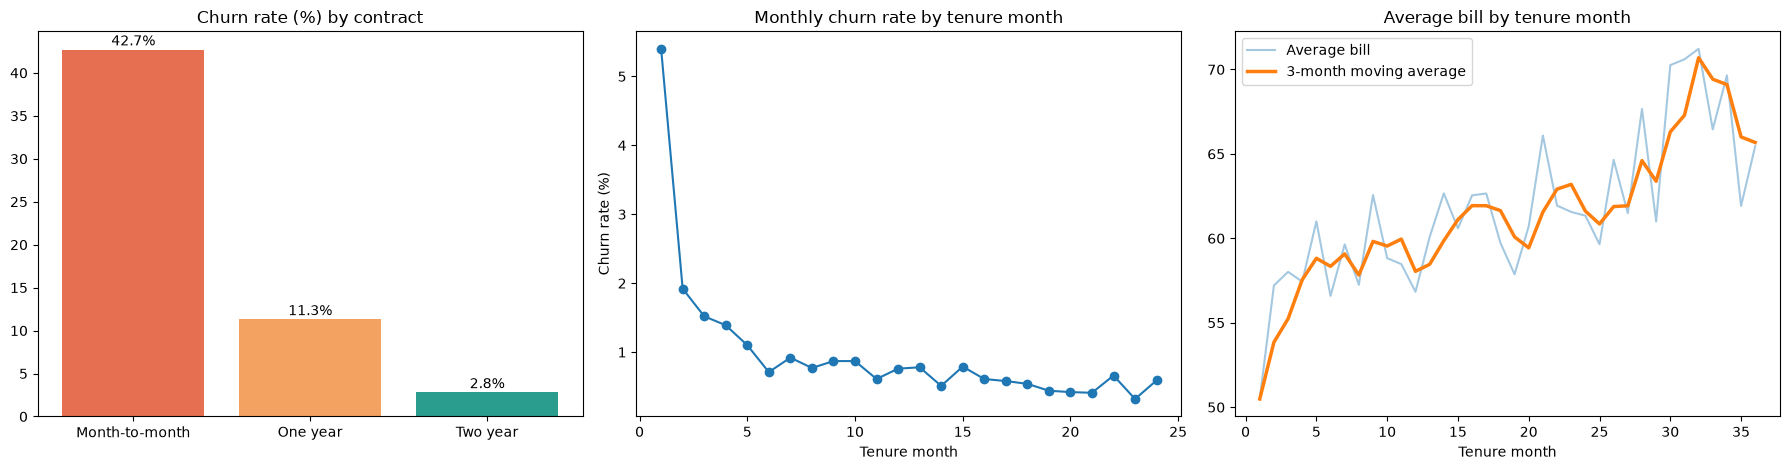

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

c = pd.read_sql_query("SELECT * FROM v_churn_by_contract ORDER BY churn_rate_pct DESC", conn)
axes[0].bar(c["contract"], c["churn_rate_pct"], color=["#e76f51", "#f4a261", "#2a9d8f"])
axes[0].set_title("Churn rate (%) by contract")
for i, v in enumerate(c["churn_rate_pct"]):
    axes[0].text(i, v + 0.5, f"{v}%", ha="center")

h = pd.read_sql_query("""
WITH by_t AS (SELECT tenure, COUNT(*) AS n, SUM(churn_flag) AS ch FROM accounts WHERE tenure >= 1 GROUP BY tenure),
risk AS (SELECT tenure, ch, SUM(n) OVER (ORDER BY tenure ROWS BETWEEN CURRENT ROW AND UNBOUNDED FOLLOWING) AS at_risk FROM by_t)
SELECT tenure, ROUND(100.0 * ch / at_risk, 2) AS rate FROM risk WHERE tenure <= 24 ORDER BY tenure""", conn)
axes[1].plot(h["tenure"], h["rate"], marker="o")
axes[1].set_title("Monthly churn rate by tenure month")
axes[1].set_xlabel("Tenure month"); axes[1].set_ylabel("Churn rate (%)")

m = pd.read_sql_query("""
WITH t AS (SELECT tenure, AVG(monthly_charges) AS b FROM accounts WHERE tenure BETWEEN 1 AND 36 GROUP BY tenure)
SELECT tenure, b, AVG(b) OVER (ORDER BY tenure ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS ma FROM t""", conn)
axes[2].plot(m["tenure"], m["b"], alpha=0.4, label="Average bill")
axes[2].plot(m["tenure"], m["ma"], linewidth=2.5, label="3-month moving average")
axes[2].set_title("Average bill by tenure month"); axes[2].set_xlabel("Tenure month"); axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "sql_insights_overview.png", dpi=120)
plt.show()

### Key insights (calculated from your data, so they always match your results)

In [48]:
c  = pd.read_sql_query("SELECT * FROM v_churn_by_contract ORDER BY churn_rate_pct DESC", conn)
seg = pd.read_sql_query("""
SELECT CASE WHEN contract='Month-to-month' AND internet_service='Fiber optic' AND tenure<=12 THEN 'month-to-month + fiber + first year'
            ELSE 'everyone else' END AS grp, COUNT(*) AS n, ROUND(100.0*AVG(churn_flag),1) AS rate
FROM v_customer_360 GROUP BY grp ORDER BY rate DESC""", conn)
lost = pd.read_sql_query("""
SELECT contract, ROUND(SUM(monthly_charges),2) AS lost FROM accounts WHERE churn='Yes' GROUP BY contract ORDER BY lost DESC""", conn)
risk = pd.read_sql_query("SELECT COUNT(*) AS n, ROUND(SUM(monthly_charges),2) AS rev FROM v_high_value_at_risk", conn)
early = pd.read_sql_query("SELECT ROUND(100.0*AVG(churn_flag),1) AS r FROM accounts WHERE tenure <= 12", conn)["r"][0]
late  = pd.read_sql_query("SELECT ROUND(100.0*AVG(churn_flag),1) AS r FROM accounts WHERE tenure > 48", conn)["r"][0]

print(f"1. Contract type drives churn: {c.iloc[0]['contract']} churns at {c.iloc[0]['churn_rate_pct']}% vs {c.iloc[-1]['contract']} at {c.iloc[-1]['churn_rate_pct']}%.")
print(f"2. New customers leave most: {early}% churn in the first 12 months vs {late}% after 48 months.")
print(f"3. Highest-risk group ({seg.iloc[0]['grp']}): {seg.iloc[0]['rate']}% churn across {int(seg.iloc[0]['n'])} customers.")
print(f"4. {lost.iloc[0]['contract']} loses the most monthly revenue to churn: {lost.iloc[0]['lost']:,}.")
print(f"5. {int(risk['n'][0])} active high-value customers match the churn profile, worth {risk['rev'][0]:,} per month: contact them first.")

1. Contract type drives churn: Month-to-month churns at 42.7% vs Two year at 2.8%.
2. New customers leave most: 47.4% churn in the first 12 months vs 9.5% after 48 months.
3. Highest-risk group (month-to-month + fiber + first year): 70.2% churn across 916 customers.
4. Month-to-month loses the most monthly revenue to churn: 120,847.1.
5. 125 active high-value customers match the churn profile, worth 11,114.5 per month: contact them first.


# PART I: Export for Task 3 (Dashboards)

In [49]:
out_dir = CSV_PATH.parent
exports = {
    "sql_customer_360.csv":      "SELECT * FROM v_customer_360",
    "sql_churn_by_contract.csv": "SELECT * FROM v_churn_by_contract",
    "sql_high_value_at_risk.csv": "SELECT * FROM v_high_value_at_risk",
}
for name, sql in exports.items():
    d = pd.read_sql_query(sql, conn)
    d.to_csv(out_dir / name, index=False)
    print(f"Saved {name:28s} rows: {len(d):,}")

conn.close()
print("\nDatabase connection closed. Task 2 complete!")

Saved sql_customer_360.csv         rows: 7,043
Saved sql_churn_by_contract.csv    rows: 3
Saved sql_high_value_at_risk.csv   rows: 125

Database connection closed. Task 2 complete!
